# Three Region Experiment

Dataset with sequences divided into three regions:
- Prefix: disambiguating content, same length but different vocab sizes
  - Low vocab -> Low disambiguating power (interference)
  - High vocab -> High disambiguating power  (interference)
- Suffix-1: shared evaluation target (same vocab/length across datasets)
- Suffix-2: compensating region to maintain iso-information
  - Fix vocab size to same vocab size as `Suffix-1` but vary length to maintain total information content per sequence.

This tests whether prefix disambiguating power affects memorization
when controlling for total information content and suffix-1 characteristics.

Suffix-2 maintains iso-information during training, but evaluation focuses exclusively on suffix-1 exact match.

Dataset configurations: 

| Dataset | Prefix V | Prefix L | Suffix1 V | Suffix1 L | Suffix2 V | Suffix2 L | Total L | Total Bits |
|---------|----------|----------|-----------|-----------|-----------|-----------|---------|------------|
| A1      | 16       | 50       | 128       | 50        | 128       | 64        | 164     | 998.00     |
| B1      | 1024     | 50       | 128       | 50        | 128       | 21        | 121     | 997.00     |

**Bits difference:** `1.0000`

**Each region has non-overlapping vocabulary tokens**

In [1]:
import sys

sys.path.append("..")

from analysis.utils import get_runs_data, show_config_differences
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="darkgrid")

In [2]:
data = get_runs_data(
    tag="interference-test",
    project="memorization",
    metrics=[
        "train/exact_match_repeated",
        "train/loss_total_suffix2",
        "train/loss_total_suffix1",
        "train/loss_total_prefix",
        "train/loss_total",
    ],
)
show_config_differences(data)

Found 2 runs with tag 'interference-test'


,cfg.dataset.length,cfg.dataset.suffix2_length,cfg.dataset.prefix_vocab_size
_run_id,,,
ads41wkk,164,64,16
pk13a8a0,121,21,1024


In [3]:
def plot_metric(data, metric_name, ylabel):
    groups = data.groupby(
        ["cfg.dataset.prefix_vocab_size", "cfg.dataset.suffix2_length"]
    )[[metric_name, "train/global_step"]]
    for (prefix_vocab, suffix_2_len), group in groups:
        steps = group["train/global_step"].to_list()
        exact_match = group[metric_name].to_list()
        label = f"Prefix Vocab={prefix_vocab}, Suffix-2 Length={suffix_2_len}"
        plt.plot(steps, exact_match, label=label, linewidth=2)

    plt.xlabel("Step", fontsize=18)
    plt.ylabel(ylabel, fontsize=18)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=14)
    plt.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, -0.15),
        fontsize=16,
        ncol=1,
        frameon=False,
    )
    plt.tight_layout()
    plt.show()

`Suffix-1` is memorized faster in the dataset where the sequence prefixes have higher disambiguating power (higher vocab), or lower interference, as expexted. Next, we examine the losses per region. 

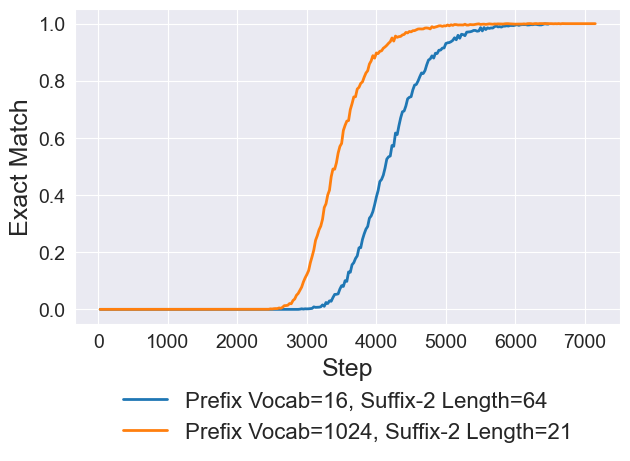

In [4]:
plot_metric(data, "train/exact_match_repeated", "Exact Match")

The loss in the `Suffix-1` region goes down faster in the dataset where the sequence prefixes have higher disambiguating power (higher vocab) as expected since this dataset is memorized faster.

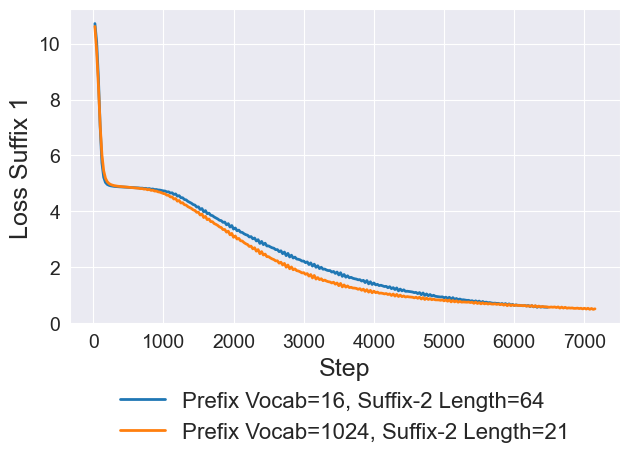

In [5]:
plot_metric(data, "train/loss_total_suffix1", "Loss Suffix 1")

The prefix loss plateaus at a higher value in the dataset with higher prefix vocab size as expected since, in this case, the prefix is "harder to guess". However, we observe that the guessing phase is shorter. 

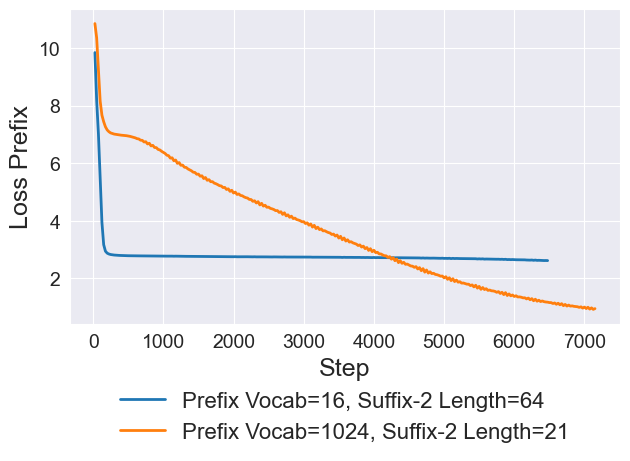

In [6]:
plot_metric(data, "train/loss_total_prefix", "Loss Prefix")

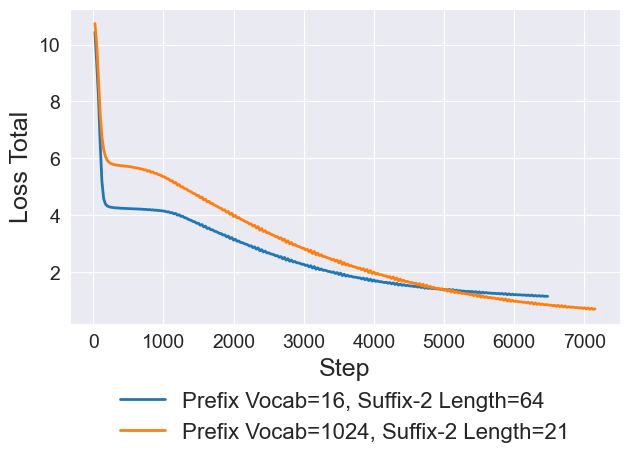

In [7]:
plot_metric(data, "train/loss_total", "Loss Total")